#### **Biliotecas**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd 
import numpy as np

from projeto_ml.univariada import Exploratoria

import seaborn as sns
import matplotlib.pyplot as plt

import warnings

pd.set_option('display.max_columns',None)

sns.set()


warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('../data/raw/churn_simples.csv')

In [4]:
round(df['Churn'].value_counts(normalize=True) * 100, 2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [5]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df2 = (
    df
        .assign(
            TotalCharges = lambda x: np.where(x['TotalCharges'] == " ", np.nan, x['TotalCharges']).astype('float'),
            Churn = lambda x: np.where(x['Churn']=='No', 0, 1)
        )
)

df2.to_parquet('../data/bronze/churn_clear.parquet')

In [8]:
# Instanciando a classe para análise exploratória
exp = Exploratoria(df2)

###  **UNIVARIADA**

#### **NUMERICAS**

##### **tenure**

Estatísticas Descritivas: tenure


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0


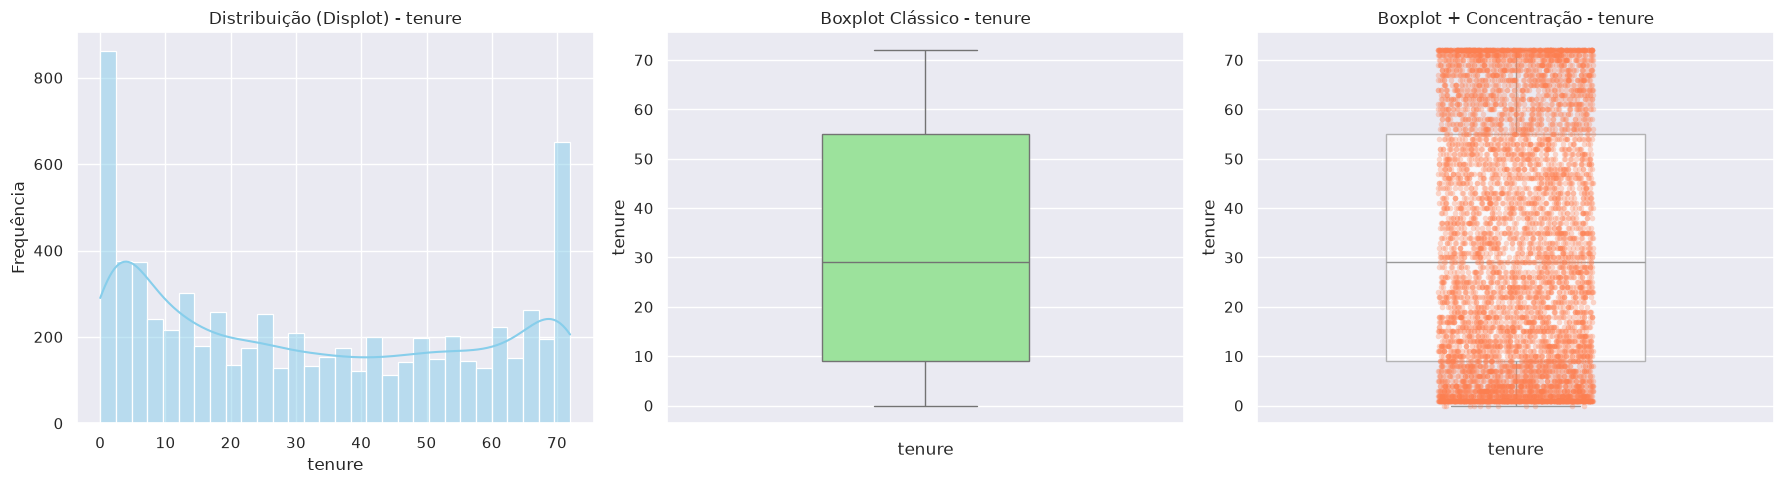

In [9]:
exp.analise_univariada_numerica('tenure')

##### **MonthlyCharges**

Estatísticas Descritivas: MonthlyCharges


,count,mean,std,min,25%,50%,75%,max
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


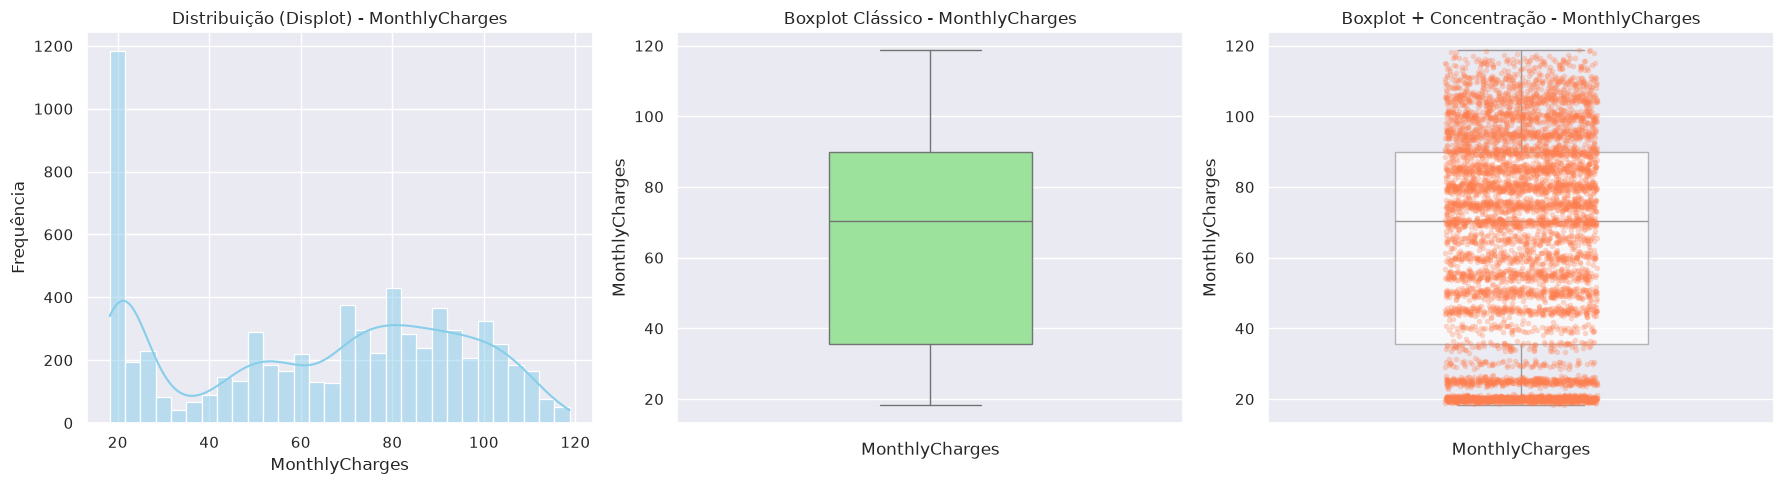

In [10]:
exp.analise_univariada_numerica('MonthlyCharges')

##### **TotalCharges**

Estatísticas Descritivas: TotalCharges


,count,mean,std,min,25%,50%,75%,max
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8


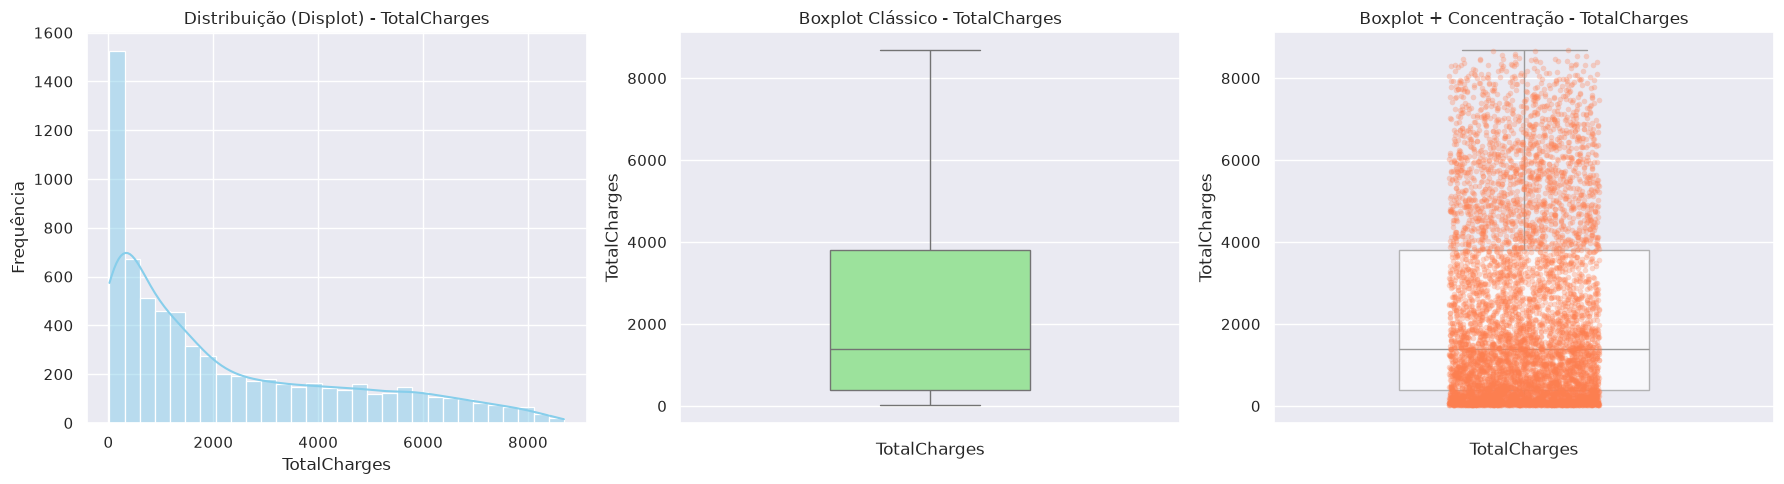

In [11]:
exp.analise_univariada_numerica('TotalCharges')

#### **CATEGORICAS**

##### **gender**

Frequência: gender


,contagem,proporcao_%
gender,,
Male,3555,50.48
Female,3488,49.52


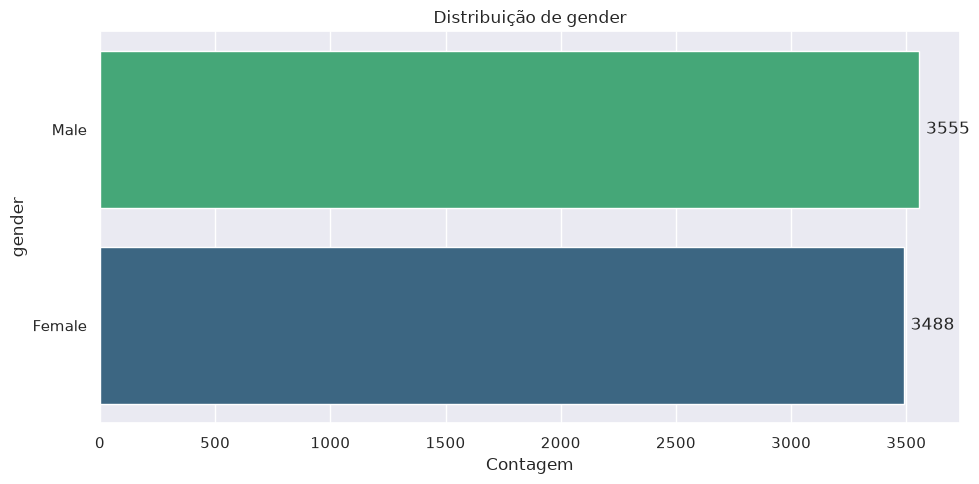

In [12]:
exp.analise_univariada_categorica('gender')

#### **Partner**

Frequência: Partner


,contagem,proporcao_%
Partner,,
No,3641,51.7
Yes,3402,48.3


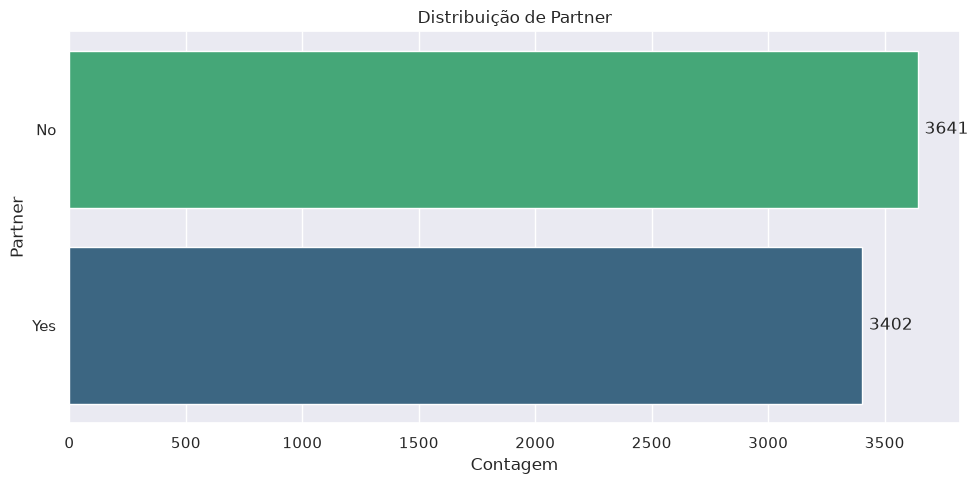

In [13]:
exp.analise_univariada_categorica(coluna = 'Partner')

##### **Dependents**

Frequência: Dependents


,contagem,proporcao_%
Dependents,,
No,4933,70.04
Yes,2110,29.96


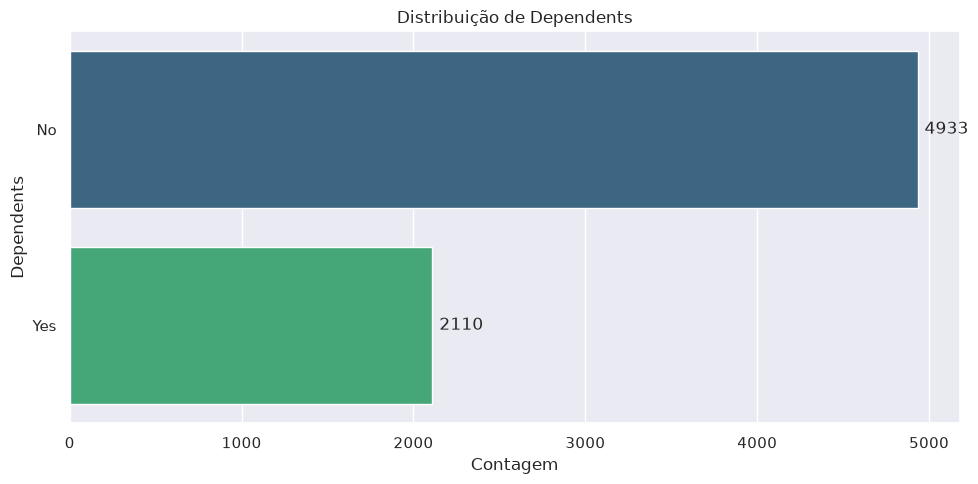

In [14]:
exp.analise_univariada_categorica(coluna = 'Dependents')

##### **PhoneService**

Frequência: PhoneService


,contagem,proporcao_%
PhoneService,,
Yes,6361,90.32
No,682,9.68


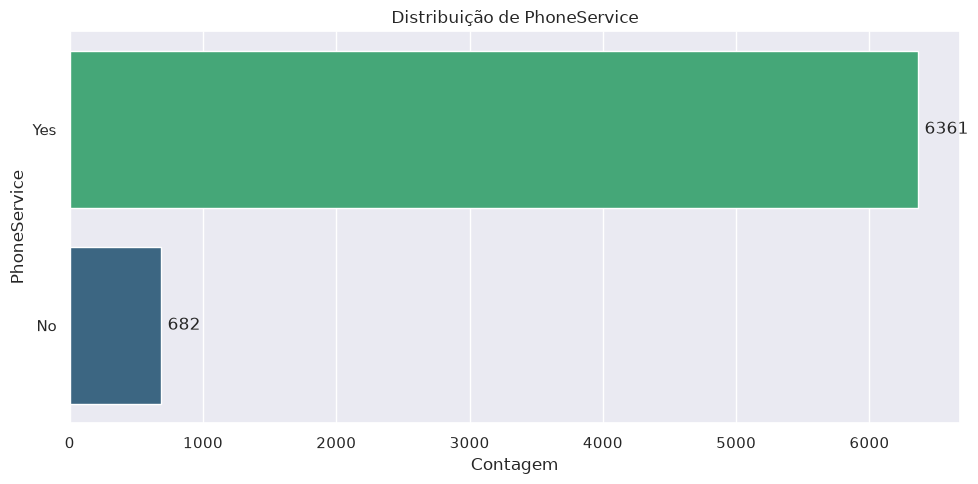

In [15]:
exp.analise_univariada_categorica(coluna = 'PhoneService')

##### **MultipleLines**

Frequência: MultipleLines


,contagem,proporcao_%
MultipleLines,,
No,3390,48.13
Yes,2971,42.18
No phone service,682,9.68


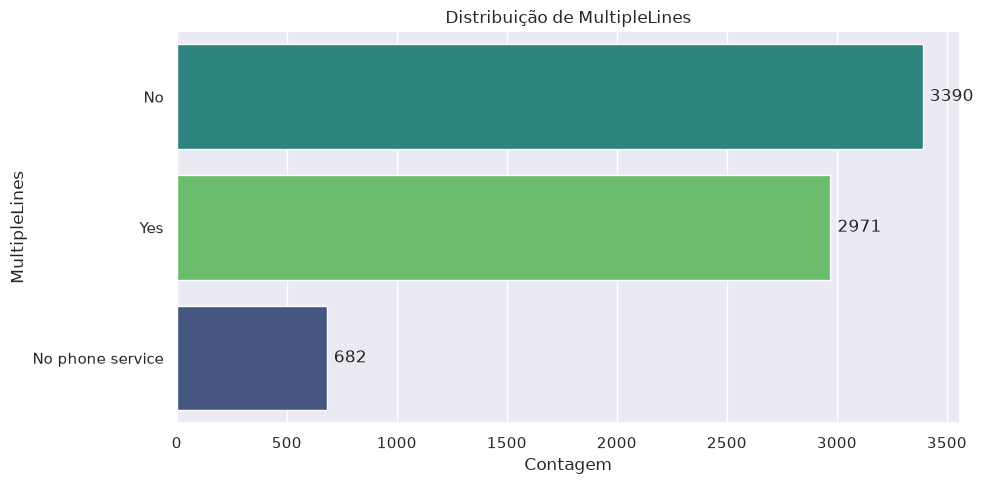

In [16]:
exp.analise_univariada_categorica('MultipleLines')

##### **InternetService**

Frequência: InternetService


,contagem,proporcao_%
InternetService,,
Fiber optic,3096,43.96
DSL,2421,34.37
No,1526,21.67


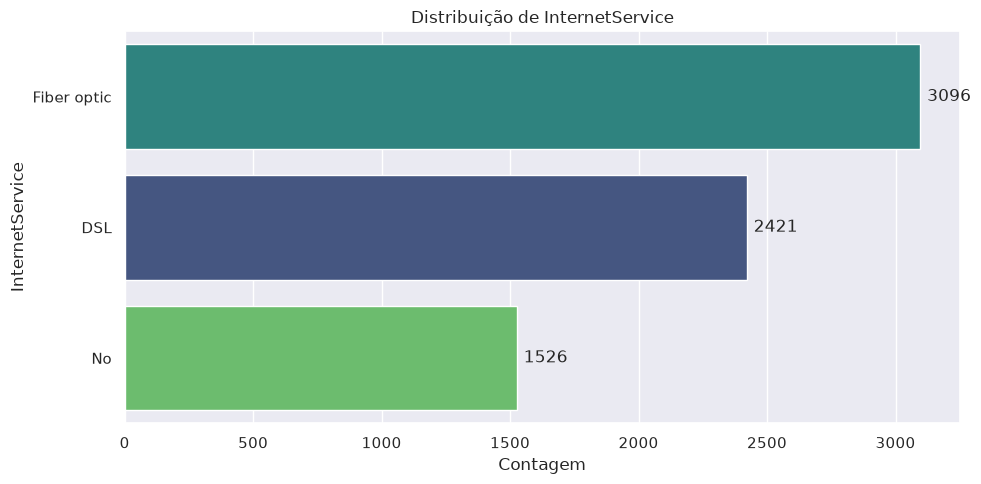

In [17]:
exp.analise_univariada_categorica('InternetService')

##### **OnlineSecurity**

Frequência: OnlineSecurity


,contagem,proporcao_%
OnlineSecurity,,
No,3498,49.67
Yes,2019,28.67
No internet service,1526,21.67


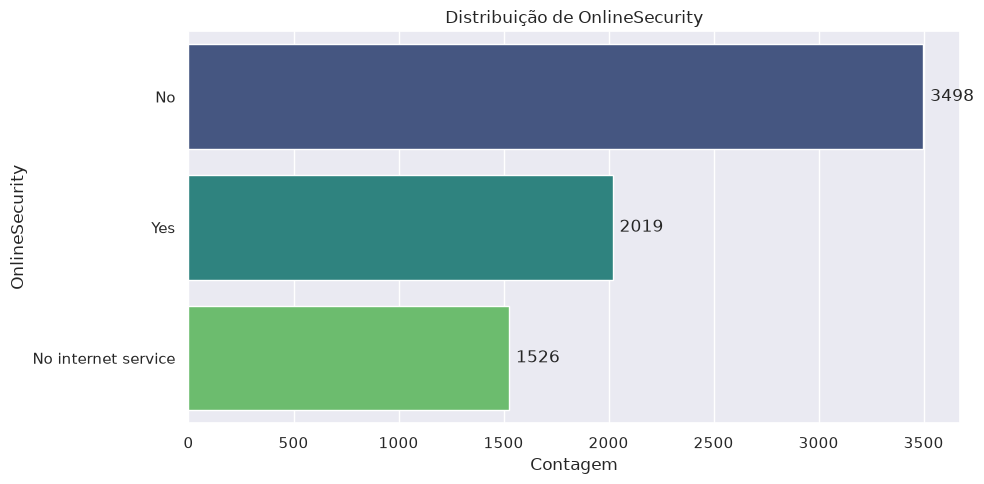

In [18]:
exp.analise_univariada_categorica('OnlineSecurity')

##### **OnlineBackup**

Frequência: OnlineBackup


,contagem,proporcao_%
OnlineBackup,,
No,3088,43.84
Yes,2429,34.49
No internet service,1526,21.67


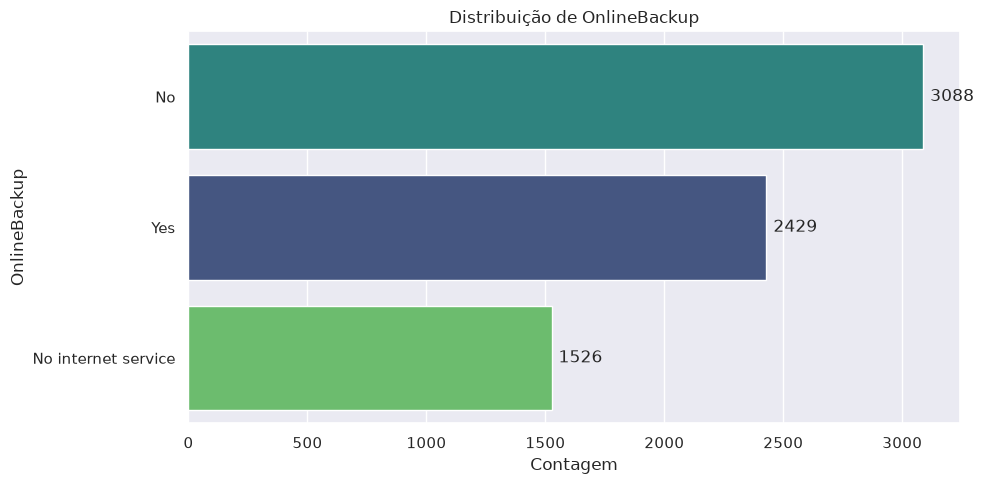

In [19]:
exp.analise_univariada_categorica('OnlineBackup')

##### **DeviceProtection**

Frequência: DeviceProtection


,contagem,proporcao_%
DeviceProtection,,
No,3095,43.94
Yes,2422,34.39
No internet service,1526,21.67


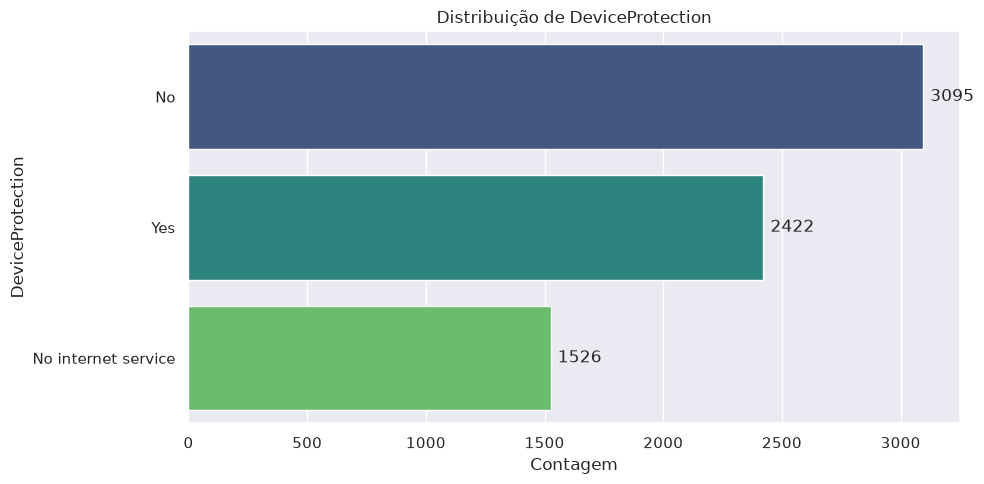

In [20]:
exp.analise_univariada_categorica('DeviceProtection')

##### **TechSupport**

Frequência: TechSupport


,contagem,proporcao_%
TechSupport,,
No,3473,49.31
Yes,2044,29.02
No internet service,1526,21.67


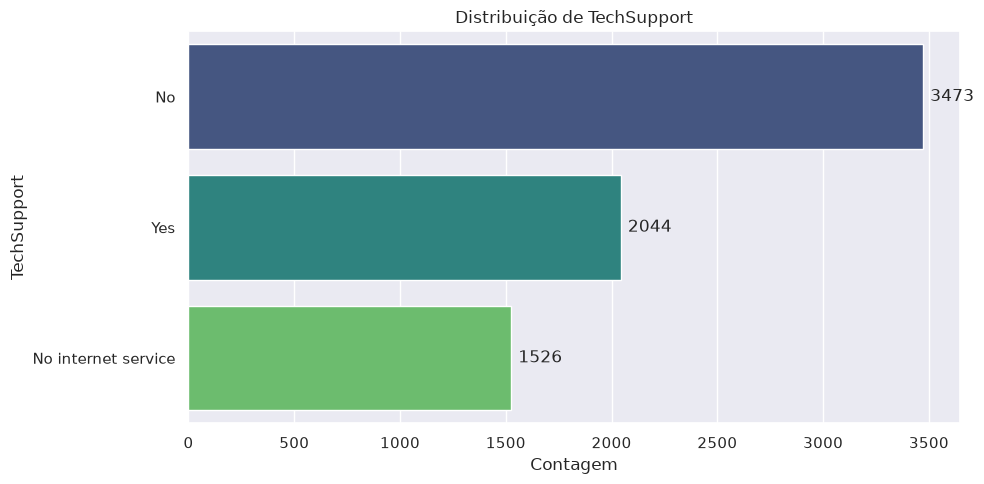

In [21]:
exp.analise_univariada_categorica('TechSupport')

##### **StreamingMovies**

Frequência: StreamingMovies


,contagem,proporcao_%
StreamingMovies,,
No,2785,39.54
Yes,2732,38.79
No internet service,1526,21.67


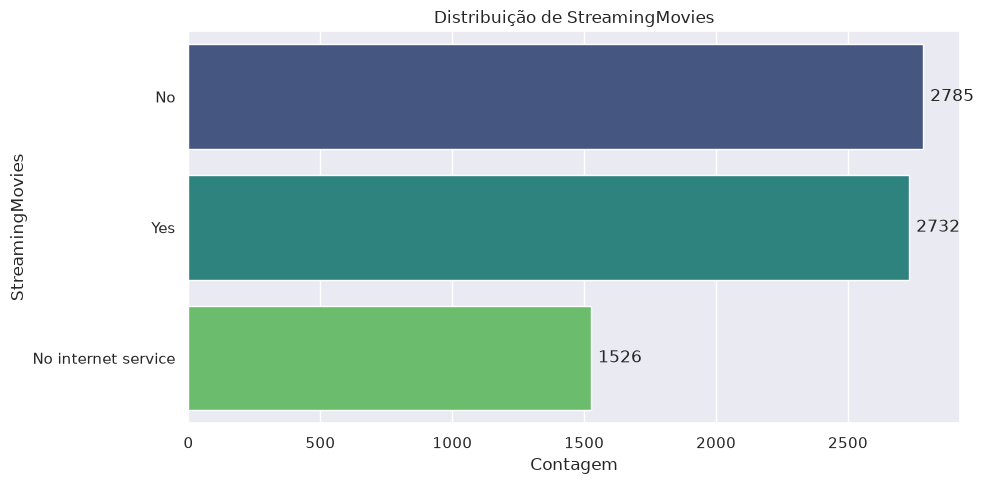

In [22]:
exp.analise_univariada_categorica('StreamingMovies')

##### **Contract**

Frequência: Contract


,contagem,proporcao_%
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91


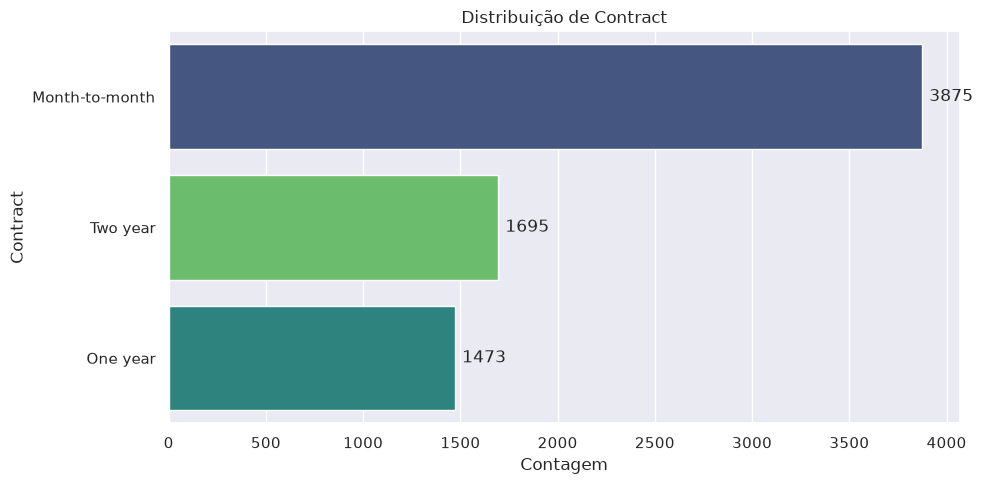

In [23]:
exp.analise_univariada_categorica('Contract')

##### **PaperlessBilling**

Frequência: PaperlessBilling


,contagem,proporcao_%
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78


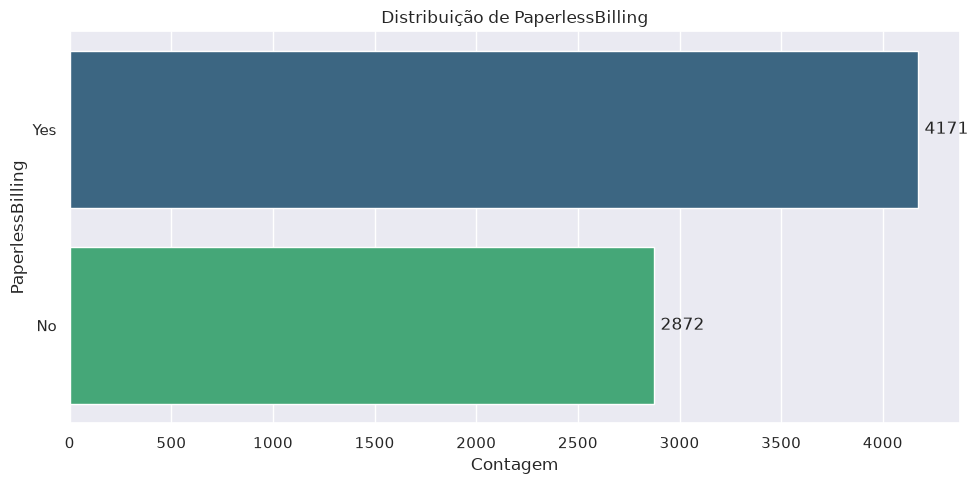

In [24]:
exp.analise_univariada_categorica('PaperlessBilling')

##### **PaymentMethod**

Frequência: PaymentMethod


,contagem,proporcao_%
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


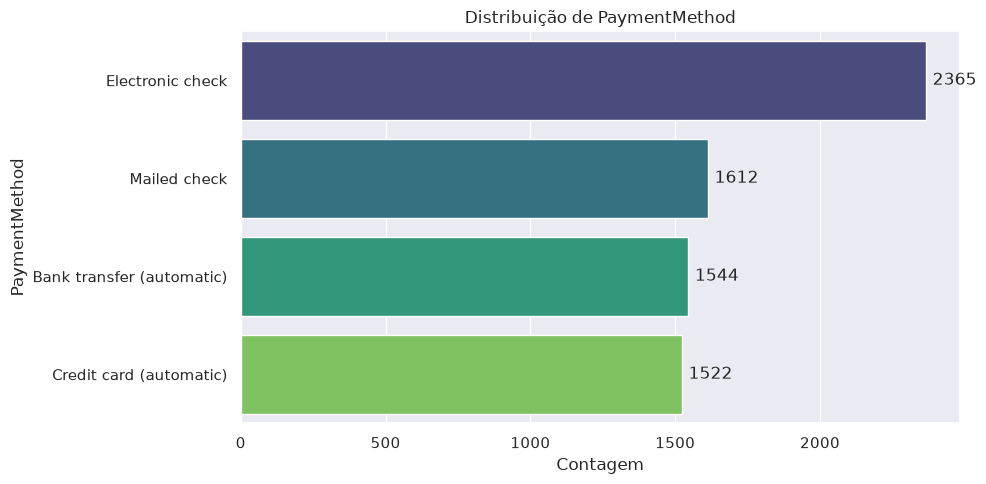

In [25]:
exp.analise_univariada_categorica('PaymentMethod')